In [361]:
%run ./functions.ipynb
random.seed(42)

### ATA-SMC

In [362]:
class Options:
    pass

N = 10000  # Run for 100, 1000, and 10000
d = 10
alpha = np.exp(-1)
repeats = 10

num_repeats = 1

# Initialize result arrays with NaNs
log_evidence_ata_smc = np.full(num_repeats, np.nan)
count_ata_smc = np.full(num_repeats, np.nan)
time_ata_smc = np.full(num_repeats, np.nan)

for i in range(num_repeats):
    
    # %%%%%%%%%%%%%%%%%%%% PERFORMING ATA-SMC %%%%%%%%%%%%%%%%%%%%%%% -1
    options = Options()
    options.N = N
    options.d = d
    options.alpha = 0.999
    options.R = repeats
    options.sig = 0.1

    np.random.seed(i)
    t_start = time.time()
    # log_unnormalized_w, normalized_w between time t and t+1
    log_evidence, count_loglike, gammavar, ess, log_unnormalized_w, normalized_w, prop_particles_inside_spike_radius_1sd, prop_particles_inside_spike_radius_2sd, prop_particles_inside_spike_radius_3sd, log_evidence_t, accept_rate_t, accept_spike_t, accept_slab_t, total_prop_spike, total_prop_slab = ATA_SMC_bespoke_RW(loglike_fn, logprior_fn, simprior_fn, options, False)
    t_elapsed = time.time() - t_start

    log_evidence_ata_smc[i] = log_evidence
    count_ata_smc[i] = count_loglike
    time_ata_smc[i] = t_elapsed

#### Diagnostic for ATA-SMC

In [363]:
# Change variable name
log_unnormalized_w_ata_smc = log_unnormalized_w
normalized_w_ata_smc = normalized_w
prop_particles_inside_spike_radius_1sd_ata_smc = prop_particles_inside_spike_radius_1sd
prop_particles_inside_spike_radius_2sd_ata_smc = prop_particles_inside_spike_radius_2sd
prop_particles_inside_spike_radius_3sd_ata_smc = prop_particles_inside_spike_radius_3sd
log_evidence_t_ata_smc = log_evidence_t
log_evidence_ata_smc = log_evidence
accept_rate_t_ata_smc = accept_rate_t
accept_spike_t_ata_smc = accept_spike_t
accept_slab_t_ata_smc = accept_slab_t
total_prop_spike_ata_smc = total_prop_spike 
total_prop_slab_ata_smc = total_prop_slab

# Check the dimension of output
print(np.exp(log_evidence_ata_smc))
print(0.3921)
print(len(ess))
print(len(gammavar[1:]))
print(len(prop_particles_inside_spike_radius_1sd_ata_smc))
print(log_unnormalized_w_ata_smc.shape)
print(normalized_w_ata_smc.shape)
print(log_evidence_t_ata_smc.shape)
print(prop_particles_inside_spike_radius_1sd_ata_smc.shape)

0.13901587635210105
0.3921
214
214
215
(214, 10000)
(214, 10000)
(214,)
(215,)


In [364]:
# Checking at the end, how many particles are in the spike radius (3sd), in the slab, and the ratio of them
print(total_prop_spike_ata_smc)
print(total_prop_slab_ata_smc)
print(total_prop_spike_ata_smc/total_prop_slab_ata_smc)

35077
64923
0.5402861851732051


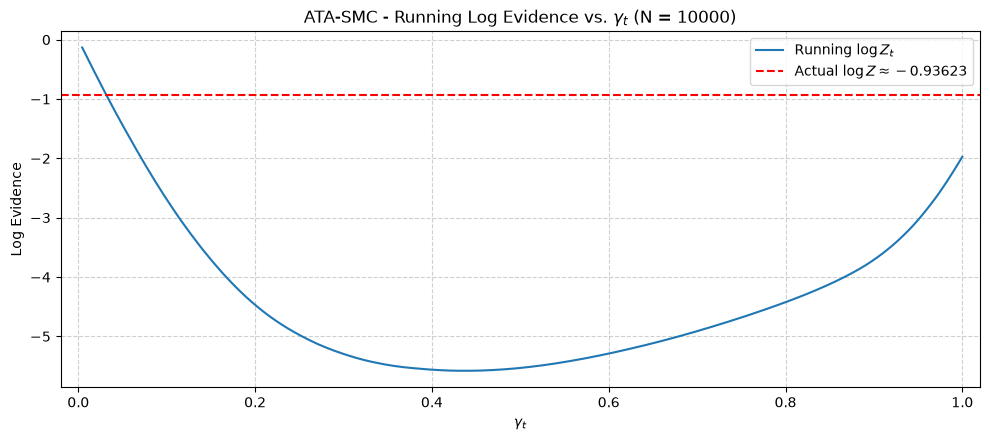

In [365]:
# Log evidence as gamma t increases from 0 to 1 (prior -> posterior)
plt.figure(figsize=(10, 4.5))
plt.plot(gammavar[1:], log_evidence_t_ata_smc, linewidth=1.5, markersize=4, label=r"Running $\log Z_t$")
plt.axhline(y=np.log(0.3921), color="r", linestyle="--", linewidth=1.5, label=r"Actual $\log Z\approx-0.93623$")
plt.xlabel(r"$\gamma_t$")
plt.ylabel("Log Evidence")
plt.title(rf"ATA-SMC - Running Log Evidence vs. $\gamma_t$ (N = {options.N})")
plt.xlim(-0.02, 1.02)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

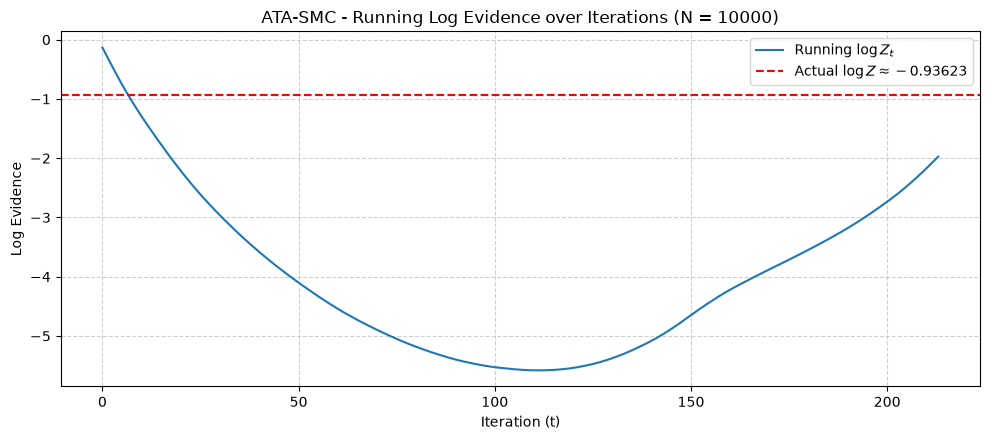

In [366]:
# Log evidences over iterations
plt.figure(figsize=(10, 4.5))
plt.plot(log_evidence_t_ata_smc, linewidth=1.5, markersize=4, label=r"Running $\log Z_t$")
plt.axhline(y=np.log(0.3921), color="r", linestyle="--", linewidth=1.5, label=r"Actual $\log Z\approx-0.93623$")
plt.xlabel(r"Iteration (t)")
plt.ylabel("Log Evidence")
plt.title(rf"ATA-SMC - Running Log Evidence over Iterations (N = {options.N})")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

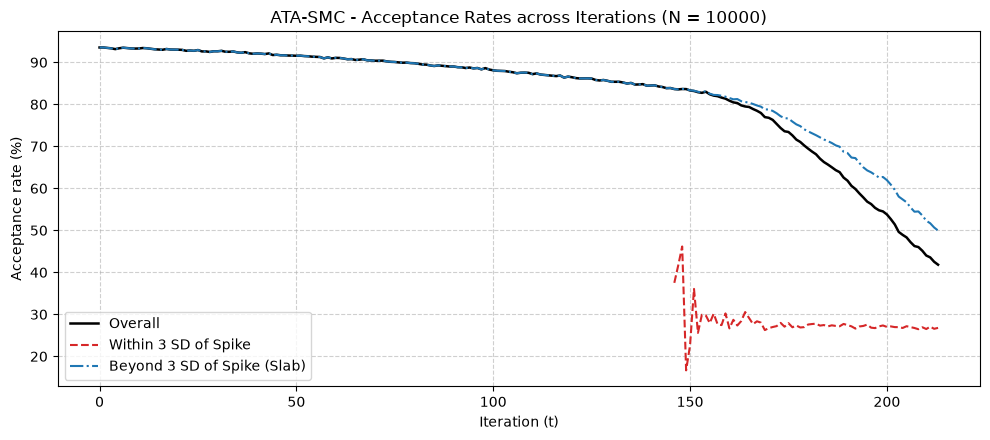

In [367]:
# Acceptance rate over iterations
# Checking at which iteration. the proposed particles are inside the spike radius (3sd)
plt.figure(figsize=(10, 4.5))

plt.plot(
    np.array(accept_rate_t_ata_smc) * 100,
    label="Overall",
    # marker="o",
    linewidth=1.8,
    markersize=4,
    color="black",
)
plt.plot(
    np.array(accept_spike_t_ata_smc) * 100,
    label="Within 3 SD of Spike",
    # marker="s",
    linestyle="--",
    linewidth=1.5,
    markersize=4,
    color="tab:red",
)
plt.plot(
    np.array(accept_slab_t_ata_smc) * 100,
    label="Beyond 3 SD of Spike (Slab)",
    # marker="^",
    linestyle="-.",
    linewidth=1.5,
    markersize=4,
    color="tab:blue",
)

plt.xlabel("Iteration (t)")
plt.ylabel("Acceptance rate (%)")
plt.title(f"ATA-SMC - Acceptance Rates across Iterations (N = {N})")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

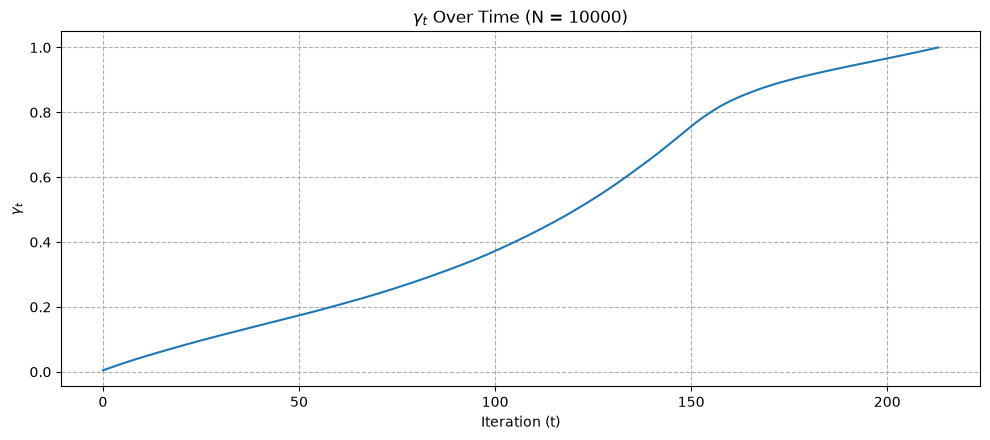

In [368]:
# Gamma t over iterations
plt.figure(figsize=(10, 4.5))
plt.plot(gammavar[1:], linewidth=1.5, markersize=4)
plt.xlabel("Iteration (t)")
plt.ylabel(r"$\gamma_t$")
plt.title(rf"$\gamma_t$ Over Time (N = {options.N})")  
plt.grid(True, linestyle="--")
plt.tight_layout()
plt.show()

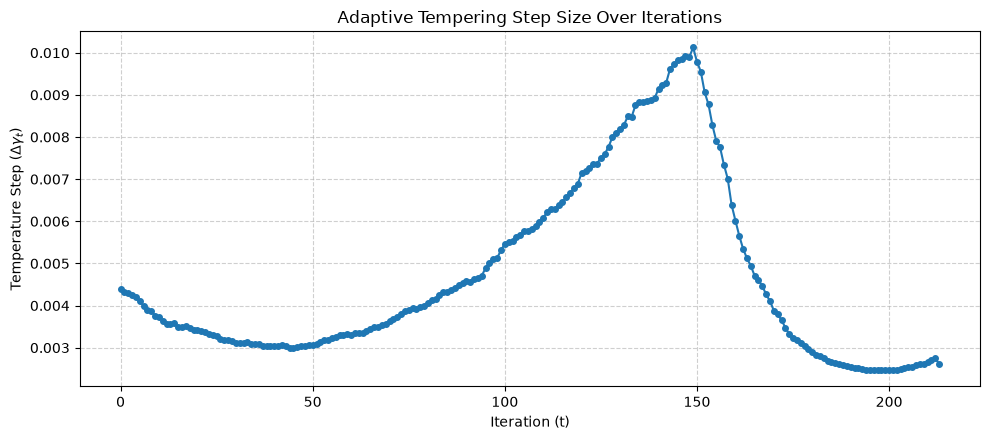

In [369]:
# Tracking changes of delta gamma t over iteration, especially when discovering particles inside the spike
delta_gamma = np.diff(gammavar)
plt.figure(figsize=(10, 4.5))
plt.plot(delta_gamma, marker="o", linewidth=1.5, markersize=4)
plt.xlabel("Iteration (t)")
plt.ylabel(r"Temperature Step ($\Delta \gamma_t$)")
plt.title("Adaptive Tempering Step Size Over Iterations")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

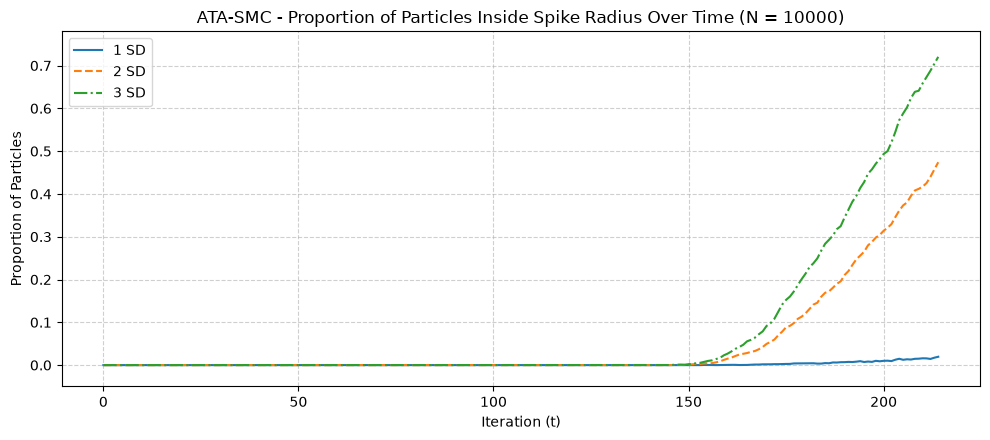

In [370]:
# Proportion of particles within 1sd, 2sd, 3sd of the spike over iterations
plt.figure(figsize=(10, 4.5))

plt.plot(
    prop_particles_inside_spike_radius_1sd_ata_smc,
    label="1 SD",
    # marker="o",
    linewidth=1.5,
    markersize=4,
    color="tab:blue",
)
plt.plot(
    prop_particles_inside_spike_radius_2sd_ata_smc,
    label="2 SD",
    # marker="s",
    linestyle="--",
    linewidth=1.5,
    markersize=4,
    color="tab:orange",
)
plt.plot(
    prop_particles_inside_spike_radius_3sd_ata_smc,
    label="3 SD",
    # marker="^",
    linestyle="-.",
    linewidth=1.5,
    markersize=4,
    color="tab:green",
)

plt.xlabel("Iteration (t)")
plt.ylabel("Proportion of Particles")
plt.title(f"ATA-SMC - Proportion of Particles Inside Spike Radius Over Time (N = {options.N})")
plt.ylim(-0.05, 0.78)  # Keeps the [0, 1] proportion scale clean and consistent
plt.legend(loc="upper left")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

In [371]:
print(gammavar.shape)
print(prop_particles_inside_spike_radius_1sd_ata_smc.shape)

(215,)
(215,)


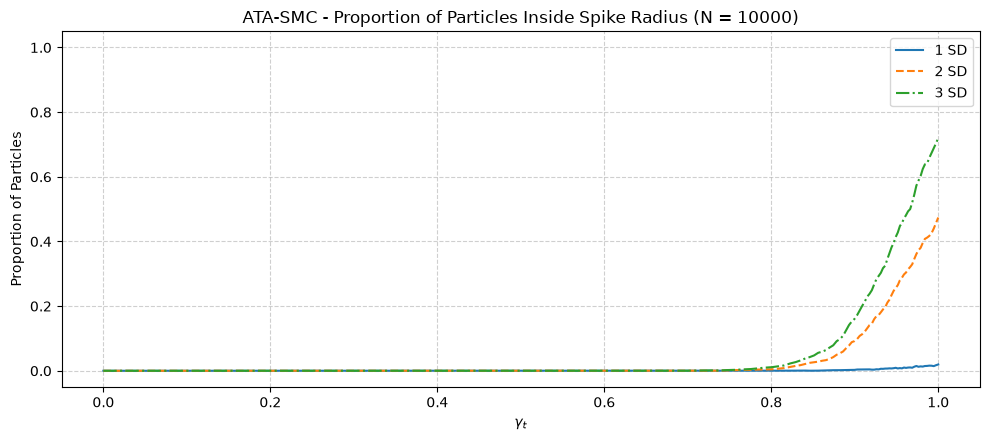

In [372]:
# Proportion of particles within 1sd, 2sd, 3sd of the spike over the increase of gamma t
plt.figure(figsize=(10, 4.5))

plt.plot(
    gammavar, 
    prop_particles_inside_spike_radius_1sd_ata_smc,
    label="1 SD",
    linewidth=1.5,
    color="tab:blue",
)
plt.plot(
    gammavar, 
    prop_particles_inside_spike_radius_2sd_ata_smc,
    label="2 SD",
    linestyle="--",
    linewidth=1.5,
    color="tab:orange",
)
plt.plot(
    gammavar, 
    prop_particles_inside_spike_radius_3sd_ata_smc,
    label="3 SD",
    linestyle="-.",
    linewidth=1.5,
    color="tab:green",
)

plt.xlabel(r"$\gamma_t$")
plt.ylabel("Proportion of Particles")
plt.title(f"ATA-SMC - Proportion of Particles Inside Spike Radius (N = {options.N})")
plt.ylim(-0.05, 1.05)
plt.legend(loc="best")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

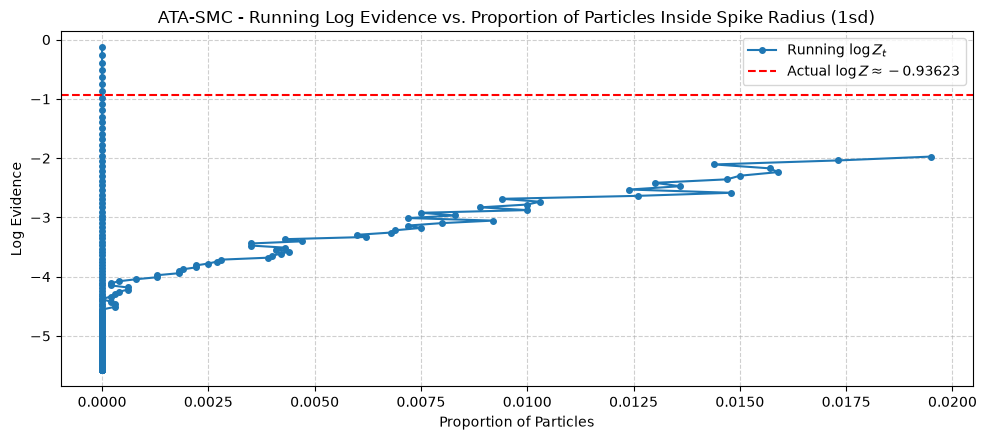

In [373]:
# How log evidence changes as the proportion of particles within 1sd of the spike changes
plt.figure(figsize=(10, 4.5))
plt.plot(prop_particles_inside_spike_radius_1sd_ata_smc[1:], log_evidence_t_ata_smc, marker="o", linewidth=1.5, markersize=4, label=r"Running $\log Z_t$")
plt.axhline(y=np.log(0.3921), color="r", linestyle="--", linewidth=1.5, label=r"Actual $\log Z\approx-0.93623$")
plt.xlabel(r"Proportion of Particles")
plt.ylabel("Log Evidence")
plt.title(rf"ATA-SMC - Running Log Evidence vs. Proportion of Particles Inside Spike Radius (1sd)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

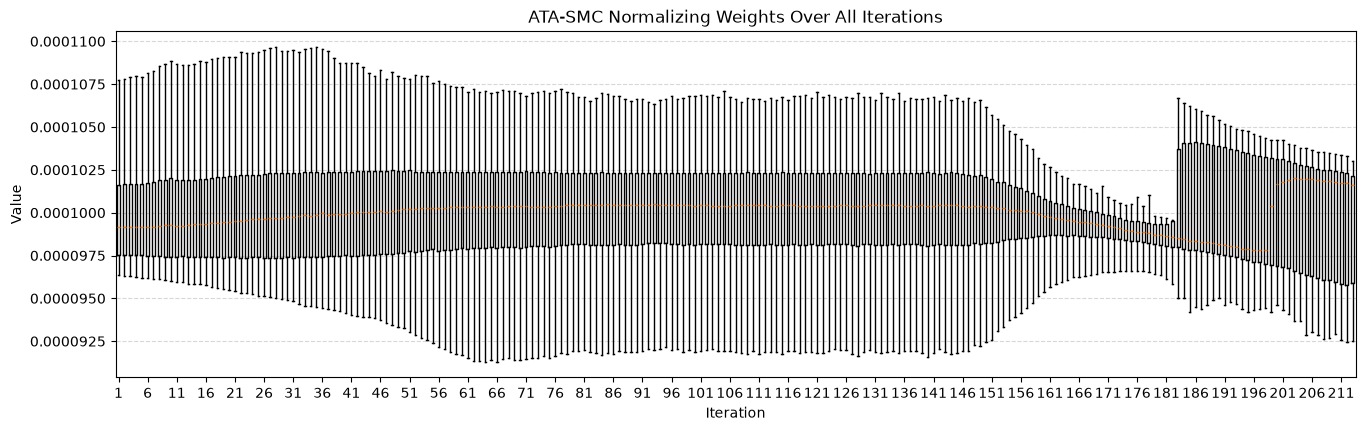

In [374]:
# Checking weight degeneracy
# Changes of normalizing weights over all iterations
data = normalized_w_ata_smc
start, end = 1, 214
subset_T = data[start : end + 1].T
iter_numbers = np.arange(start, end + 1)

plt.figure(figsize=(16, 4.5))
plt.boxplot(subset_T, showfliers=False)

# Box positions in plt.boxplot() default to 1, 2, ..., len(iter_numbers)
box_positions = np.arange(1, len(iter_numbers) + 1)

# Map every 5th box position to its true iteration number
step = 5
plt.xticks(box_positions[::step], iter_numbers[::step])

plt.xlabel("Iteration")
plt.ylabel("Value")
plt.title(f"ATA-SMC Normalizing Weights Over All Iterations")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()

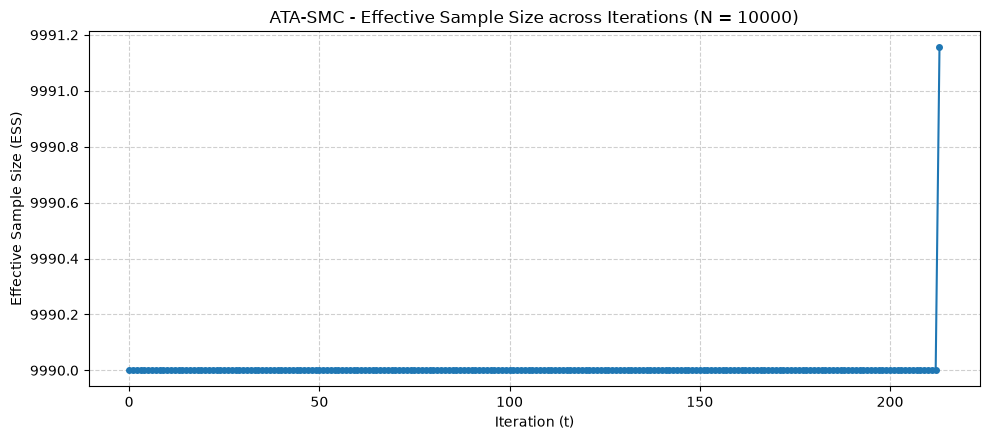

In [375]:
# Checking effective sample size over iterations
plt.figure(figsize=(10, 4.5))
plt.plot(ess, marker="o", linewidth=1.5, markersize=4)
plt.xlabel("Iteration (t)")
plt.ylabel("Effective Sample Size (ESS)")
plt.title(f"ATA-SMC - Effective Sample Size across Iterations (N = {N})")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

### ANS-SMC

In [376]:
class Options:
    pass

N = 10000  # Run for 100, 1000, and 10000
d = 10
alpha = np.exp(-1)
repeats = 10

num_repeats = 1

# Initialize result arrays with NaNs
log_evidence_ans_smc = np.full(num_repeats, np.nan)
count_ans_smc = np.full(num_repeats, np.nan)
time_ans_smc = np.full(num_repeats, np.nan)

for i in range(num_repeats):

    # %%%%%%%%%%%%%%%%%%%%%% PERFORMING ANS-SMC %%%%%%%%%%%%%%%%%%%%% -1
    options = Options()
    options.N = N
    options.d = d
    options.alpha = alpha
    options.R = repeats
    options.sig = 0.1

    np.random.seed(i)
    t_start = time.time()
    # Log unnormalized and normalized weights for the eliminated particles at each level t
    log_evidence, count_loglike, levels, log_unnormalized_w, log_normalized_w, log_evidence_t, prop_particles_inside_spike_radius_1sd, prop_particles_inside_spike_radius_2sd, prop_particles_inside_spike_radius_3sd, accept_rate_t, accept_spike_t, accept_slab_t, total_prop_spike, total_prop_slab = ANS_SMC_bespoke_RW(loglike_fn, logprior_fn, simprior_fn, options, False)
    t_elapsed = time.time() - t_start

    log_evidence_ans_smc[i] = log_evidence
    count_ans_smc[i] = count_loglike
    time_ans_smc[i] = t_elapsed

#### Diagnostic for ANS-SMC

In [377]:
# Change variable name
print(np.exp(log_evidence))
print(0.3921)
log_unnormalized_w_ans_smc = log_unnormalized_w
log_normalized_w_ans_smc = log_normalized_w
log_evidence_t_ans_smc = log_evidence_t
prop_particles_inside_spike_radius_1sd_ans_smc = prop_particles_inside_spike_radius_1sd
prop_particles_inside_spike_radius_2sd_ans_smc = prop_particles_inside_spike_radius_2sd
prop_particles_inside_spike_radius_3sd_ans_smc = prop_particles_inside_spike_radius_3sd
accept_rate_t_ans_smc = accept_rate_t
accept_spike_t_ans_smc = accept_spike_t 
accept_slab_t_ans_smc = accept_slab_t 
total_prop_spike_ans_smc = total_prop_spike 
total_prop_slab_ans_smc = total_prop_slab 
print(prop_particles_inside_spike_radius_1sd_ans_smc.shape)

0.43057697869246014
0.3921
(50,)


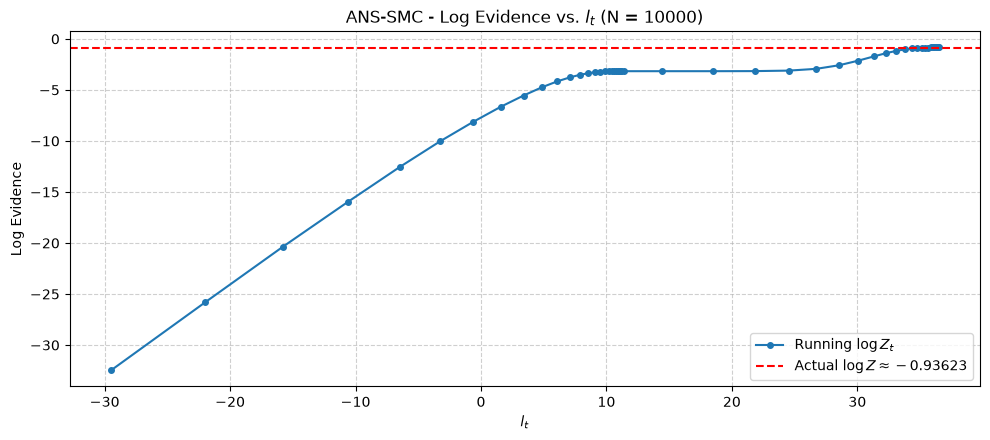

In [378]:
# Log evidence vs the log likelihood threshold (l_t)
plt.figure(figsize=(10, 4.5))
plt.plot(levels[1:], log_evidence_t_ans_smc, marker="o", linewidth=1.5, markersize=4, label=r"Running $\log Z_t$")
plt.axhline(y=np.log(0.3921), color="r", linestyle="--", linewidth=1.5, label=r"Actual $\log Z\approx-0.93623$")
plt.xlabel(r"$l_t$")
plt.ylabel("Log Evidence")
plt.title(rf"ANS-SMC - Log Evidence vs. $l_t$ (N = {options.N})")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.legend()
plt.show()

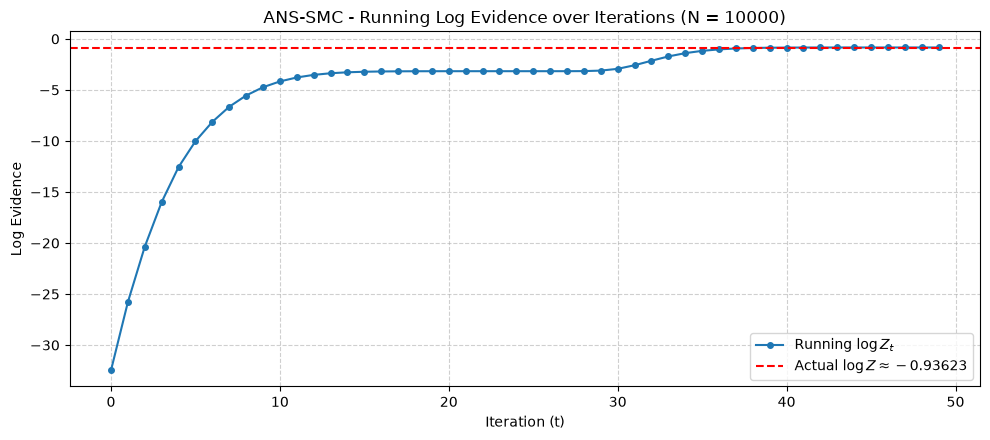

In [379]:
# Log evidence over iterations
plt.figure(figsize=(10, 4.5))
plt.plot(log_evidence_t_ans_smc , marker="o", linewidth=1.5, markersize=4, label=r"Running $\log Z_t$")
plt.axhline(y=np.log(0.3921), color="r", linestyle="--", linewidth=1.5, label=r"Actual $\log Z\approx-0.93623$")
plt.xlabel(r"Iteration (t)")
plt.ylabel("Log Evidence")
plt.title(rf"ANS-SMC - Running Log Evidence over Iterations (N = {options.N})")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

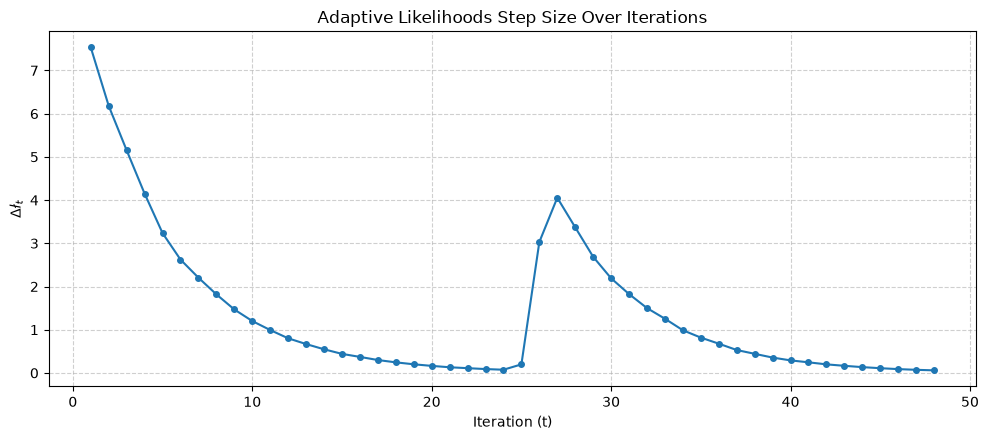

In [380]:
# Delta of log likelihood over iterations
delta_levels = np.diff(levels)
plt.figure(figsize=(10, 4.5))
plt.plot(delta_levels , marker="o", linewidth=1.5, markersize=4)
plt.xlabel("Iteration (t)")
plt.ylabel(r"$\Delta \l_t$")
plt.title("Adaptive Likelihoods Step Size Over Iterations")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

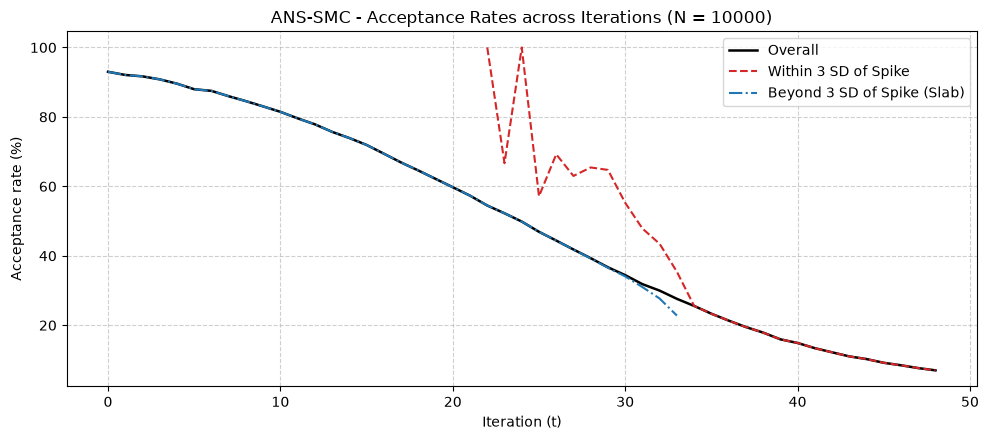

In [381]:
# Acceptance rate over iterations
# Checking at which iteration. the proposed particles are inside the spike radius (3sd)
plt.figure(figsize=(10, 4.5))
plt.plot(
    np.array(accept_rate_t_ans_smc) * 100,
    label="Overall",
    # marker="o",
    linewidth=1.8,
    markersize=4,
    color="black",
)
plt.plot(
    np.array(accept_spike_t_ans_smc) * 100,
    label="Within 3 SD of Spike",
    # marker="s",
    linestyle="--",
    linewidth=1.5,
    markersize=4,
    color="tab:red",
)
plt.plot(
    np.array(accept_slab_t_ans_smc) * 100,
    label="Beyond 3 SD of Spike (Slab)",
    # marker="^",
    linestyle="-.",
    linewidth=1.5,
    markersize=4,
    color="tab:blue",
)

plt.xlabel("Iteration (t)")
plt.ylabel("Acceptance rate (%)")
plt.title(f"ANS-SMC - Acceptance Rates across Iterations (N = {N})")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

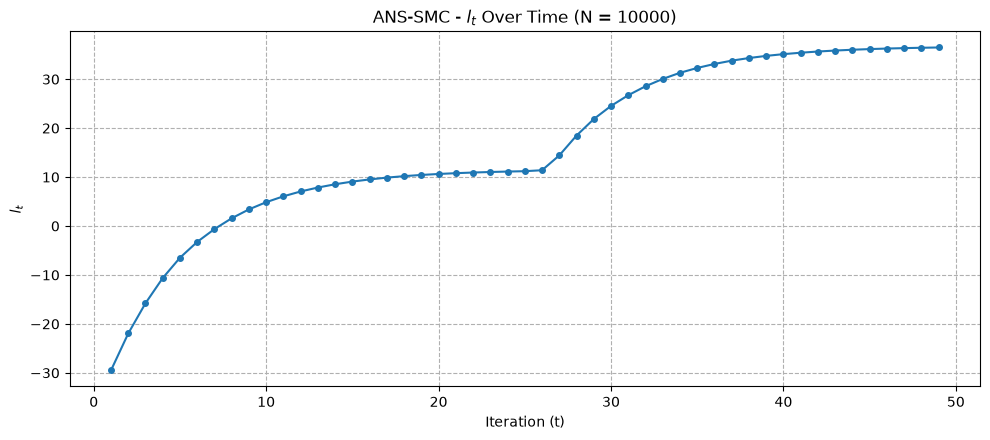

In [ ]:
# Log likelihood thresholds over time
plt.figure(figsize=(10, 4.5))
plt.plot(levels, marker="o", linewidth=1.5, markersize=4)
plt.xlabel("Iteration (t)")
plt.ylabel(r"$l_t$")
plt.title(rf"ANS-SMC - $l_t$ Over Time (N = {options.N})")
plt.grid(True, linestyle="--")
plt.tight_layout()
plt.show()

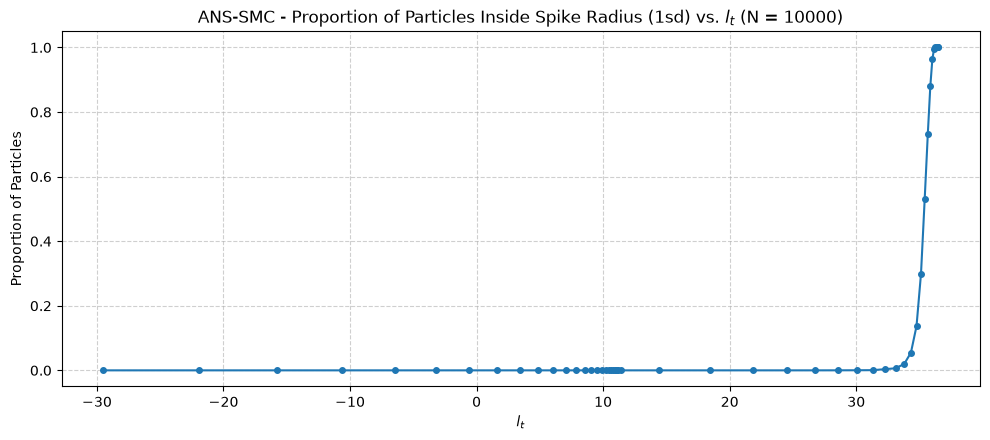

In [383]:
# Proportion of Particles Inside Spike Radius (1sd) vs. the log likelihood thresholds
plt.figure(figsize=(10, 4.5))
plt.plot(levels[1:], prop_particles_inside_spike_radius_1sd_ans_smc, marker="o", linewidth=1.5, markersize=4)
plt.xlabel(r"$l_t$")
plt.ylabel("Proportion of Particles")
plt.title(rf"ANS-SMC - Proportion of Particles Inside Spike Radius (1sd) vs. $l_t$ (N = {options.N})")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

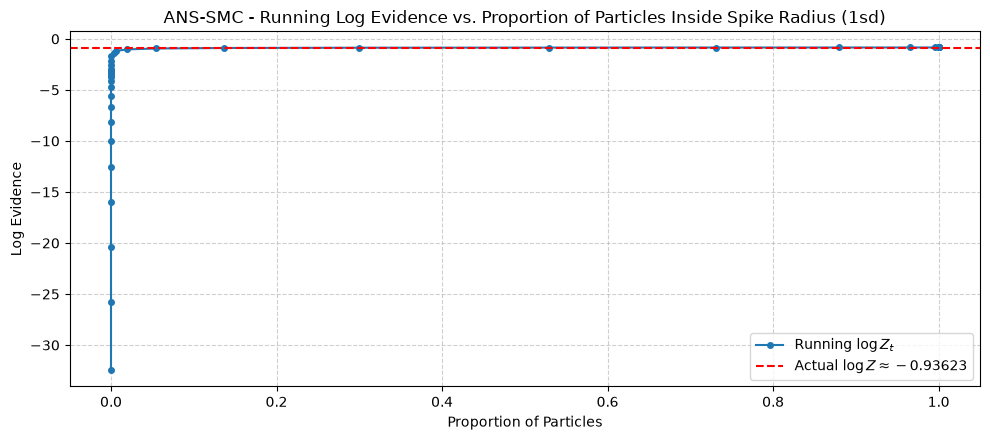

In [384]:
# Log Evidence vs. Proportion of Particles Inside Spike Radius (1sd)
plt.figure(figsize=(10, 4.5))
plt.plot(prop_particles_inside_spike_radius_1sd_ans_smc, log_evidence_t_ans_smc, marker="o", linewidth=1.5, markersize=4, label=r"Running $\log Z_t$")
plt.axhline(y=np.log(0.3921), color="r", linestyle="--", linewidth=1.5, label=r"Actual $\log Z\approx-0.93623$")
plt.xlabel(r"Proportion of Particles")
plt.ylabel("Log Evidence")
plt.title(rf"ANS-SMC - Running Log Evidence vs. Proportion of Particles Inside Spike Radius (1sd)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

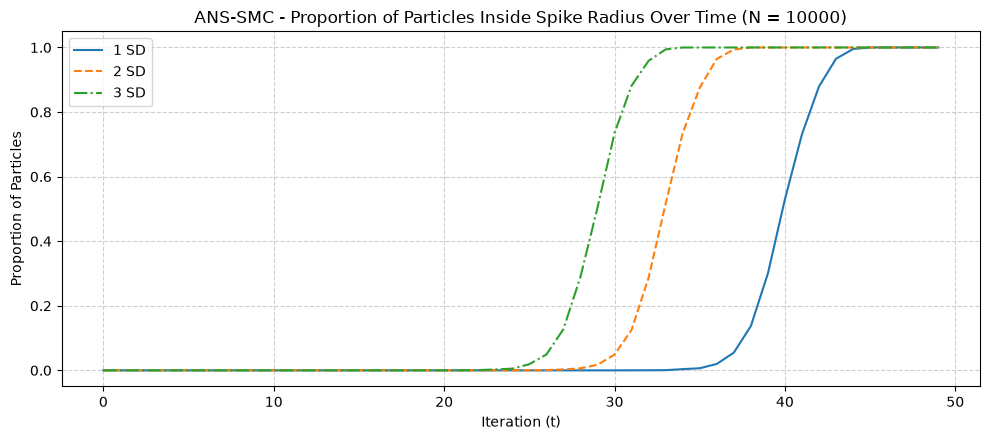

In [385]:
# Proportion of Particles Inside Spike Radius (1sd, 2sd, 3sd) Over Iterations
plt.figure(figsize=(10, 4.5))

plt.plot(
    prop_particles_inside_spike_radius_1sd_ans_smc,
    label="1 SD",
    # marker="o",
    linewidth=1.5,
    markersize=4,
    color="tab:blue",
)
plt.plot(
    prop_particles_inside_spike_radius_2sd_ans_smc,
    label="2 SD",
    # marker="s",
    linestyle="--",
    linewidth=1.5,
    markersize=4,
    color="tab:orange",
)
plt.plot(
    prop_particles_inside_spike_radius_3sd_ans_smc,
    label="3 SD",
    # marker="^",
    linestyle="-.",
    linewidth=1.5,
    markersize=4,
    color="tab:green",
)

plt.xlabel("Iteration (t)")
plt.ylabel("Proportion of Particles")
plt.title(f"ANS-SMC - Proportion of Particles Inside Spike Radius Over Time (N = {options.N})")
plt.ylim(-0.05, 1.05)  # Keeps the [0, 1] proportion scale clean and consistent
plt.legend(loc="upper left")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

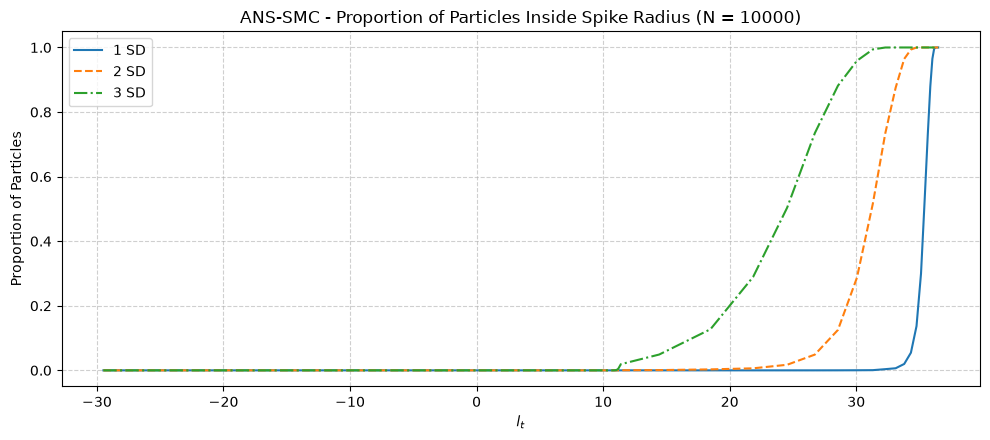

In [386]:
# Proportion of particles inside spike radius (1sd, 2sd, 3sd) across the log likelihood threshold
plt.figure(figsize=(10, 4.5))

plt.plot(
    levels[1:], 
    prop_particles_inside_spike_radius_1sd_ans_smc,
    label="1 SD",
    linewidth=1.5,
    color="tab:blue",
)
plt.plot(
    levels[1:], 
    prop_particles_inside_spike_radius_2sd_ans_smc,
    label="2 SD",
    linestyle="--",
    linewidth=1.5,
    color="tab:orange",
)
plt.plot(
    levels[1:], 
    prop_particles_inside_spike_radius_3sd_ans_smc,
    label="3 SD",
    linestyle="-.",
    linewidth=1.5,
    color="tab:green",
)

plt.xlabel(r"$l_t$")
plt.ylabel("Proportion of Particles")
plt.title(f"ANS-SMC - Proportion of Particles Inside Spike Radius (N = {options.N})")
plt.ylim(-0.05, 1.05)
plt.legend(loc="best")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

### NS-SMC

In [387]:
class Options:
    pass

N = 10000  # Run for 100, 1000, and 10000
d = 10
alpha = np.exp(-1)
repeats = 10

num_repeats = 1

# Initialize result arrays with NaNs
log_evidence_ns_smc = np.full(num_repeats, np.nan)
count_ns_smc = np.full(num_repeats, np.nan)
time_ns_smc = np.full(num_repeats, np.nan)
error_flag_ns_smc = np.full(num_repeats, np.nan)

for i in range(num_repeats):

    # %%%%%%%%%%%%%%%%%%%%%%%% PERFORMING FIXED NS-SMC %%%%%%%%%%%%%%%%%%%%%% -1
    options.N = N
    options.d = d
    options.levels = levels # levels is returned from ANS-SMC
    options.R = repeats
    options.sig = 0.1

    np.random.seed(i + num_repeats)
    t_start = time.time()
    # Log unnormalized and normalized weights for the eliminated particles at each level t
    log_evidence, count_loglike, error_flag, log_unnormalized_w, log_normalized_w, log_evidence_t, prop_particles_inside_spike_radius_1sd, prop_particles_inside_spike_radius_2sd, prop_particles_inside_spike_radius_3sd, accept_rate_t, accept_spike_t, accept_slab_t, total_prop_spike, total_prop_slab = NS_SMC_bespoke_RW(loglike_fn, logprior_fn, simprior_fn, options, False)
    t_elapsed = time.time() - t_start
    
    log_evidence_ns_smc[i] = log_evidence
    count_ns_smc[i] = count_loglike + count_ans_smc[i]
    time_ns_smc[i] = t_elapsed + time_ans_smc[i]
    error_flag_ns_smc[i] = error_flag

#### Diagnostic for NS-SMC

In [388]:
print(np.exp(log_evidence))
print(0.3921)
log_unnormalized_w_ns_smc = log_unnormalized_w
log_normalized_w_ns_smc = log_normalized_w
log_evidence_t_ns_smc = log_evidence_t
prop_particles_inside_spike_radius_1sd_ns_smc = prop_particles_inside_spike_radius_1sd
prop_particles_inside_spike_radius_2sd_ns_smc = prop_particles_inside_spike_radius_2sd
prop_particles_inside_spike_radius_3sd_ns_smc = prop_particles_inside_spike_radius_3sd
accept_rate_t_ns_smc = accept_rate_t
accept_spike_t_ns_smc = accept_spike_t 
accept_slab_t_ns_smc = accept_slab_t 
total_prop_spike_ns_smc = total_prop_spike 
total_prop_slab_ns_smc = total_prop_slab 
print(prop_particles_inside_spike_radius_1sd_ns_smc.shape)

0.35237925268173953
0.3921
(51,)


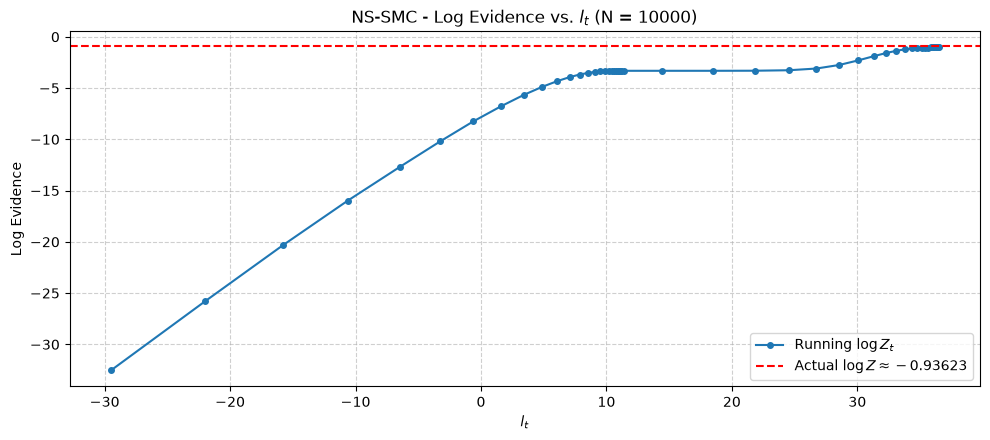

In [389]:
# Log evidence vs the log likelihood thresholds
plt.figure(figsize=(10, 4.5))
plt.plot(levels[1:], log_evidence_t_ns_smc, marker="o", linewidth=1.5, markersize=4, label=r"Running $\log Z_t$")
plt.axhline(y=np.log(0.3921), color="r", linestyle="--", linewidth=1.5, label=r"Actual $\log Z\approx-0.93623$")
plt.xlabel(r"$l_t$")
plt.ylabel("Log Evidence")
plt.title(rf"NS-SMC - Log Evidence vs. $l_t$ (N = {options.N})")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.legend()
plt.show()

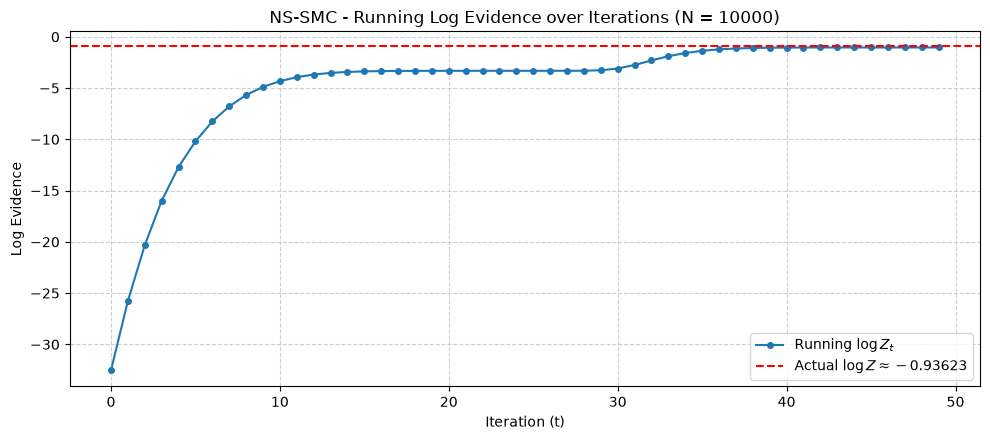

In [390]:
# Log evidence over iterations
plt.figure(figsize=(10, 4.5))
plt.plot(log_evidence_t_ns_smc , marker="o", linewidth=1.5, markersize=4, label=r"Running $\log Z_t$")
plt.axhline(y=np.log(0.3921), color="r", linestyle="--", linewidth=1.5, label=r"Actual $\log Z\approx-0.93623$")
plt.xlabel(r"Iteration (t)")
plt.ylabel("Log Evidence")
plt.title(rf"NS-SMC - Running Log Evidence over Iterations (N = {options.N})")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

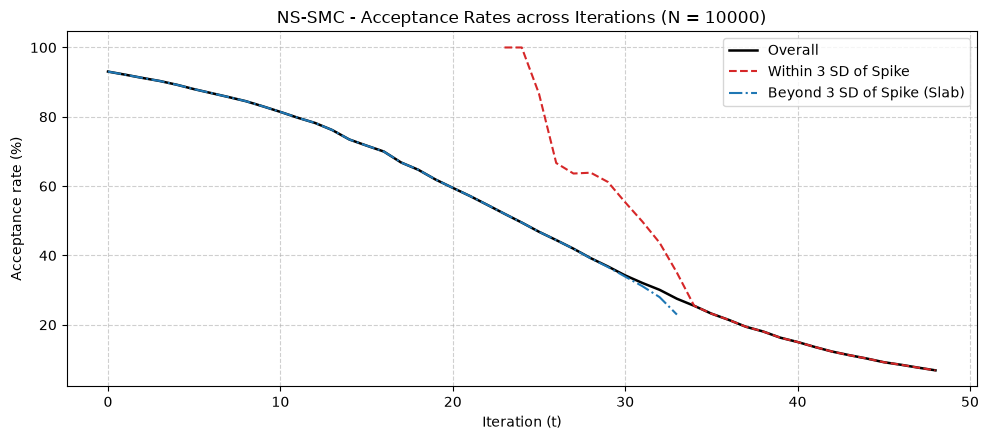

In [391]:
# Acceptance rate over iterations
# Checking at which iteration. the proposed particles are inside the spike radius (3sd)
plt.figure(figsize=(10, 4.5))

plt.plot(
    np.array(accept_rate_t_ns_smc) * 100,
    label="Overall",
    # marker="o",
    linewidth=1.8,
    markersize=4,
    color="black",
)
plt.plot(
    np.array(accept_spike_t_ns_smc) * 100,
    label="Within 3 SD of Spike",
    # marker="s",
    linestyle="--",
    linewidth=1.5,
    markersize=4,
    color="tab:red",
)
plt.plot(
    np.array(accept_slab_t_ns_smc) * 100,
    label="Beyond 3 SD of Spike (Slab)",
    # marker="^",
    linestyle="-.",
    linewidth=1.5,
    markersize=4,
    color="tab:blue",
)

plt.xlabel("Iteration (t)")
plt.ylabel("Acceptance rate (%)")
plt.title(f"NS-SMC - Acceptance Rates across Iterations (N = {N})")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

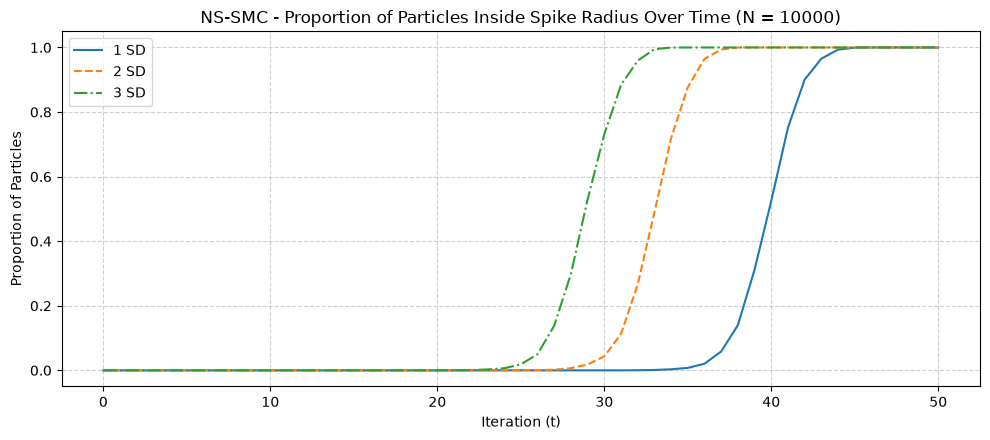

In [392]:
# Proportion of Particles Inside Spike Radius (1sd, 2sd, 3sd) Over Iterations
plt.figure(figsize=(10, 4.5))

plt.plot(
    prop_particles_inside_spike_radius_1sd_ns_smc,
    label="1 SD",
    # marker="o",
    linewidth=1.5,
    markersize=4,
    color="tab:blue",
)
plt.plot(
    prop_particles_inside_spike_radius_2sd_ns_smc,
    label="2 SD",
    # marker="s",
    linestyle="--",
    linewidth=1.5,
    markersize=4,
    color="tab:orange",
)
plt.plot(
    prop_particles_inside_spike_radius_3sd_ns_smc,
    label="3 SD",
    # marker="^",
    linestyle="-.",
    linewidth=1.5,
    markersize=4,
    color="tab:green",
)

plt.xlabel("Iteration (t)")
plt.ylabel("Proportion of Particles")
plt.title(f"NS-SMC - Proportion of Particles Inside Spike Radius Over Time (N = {options.N})")
plt.ylim(-0.05, 1.05)  # Keeps the [0, 1] proportion scale clean and consistent
plt.legend(loc="upper left")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

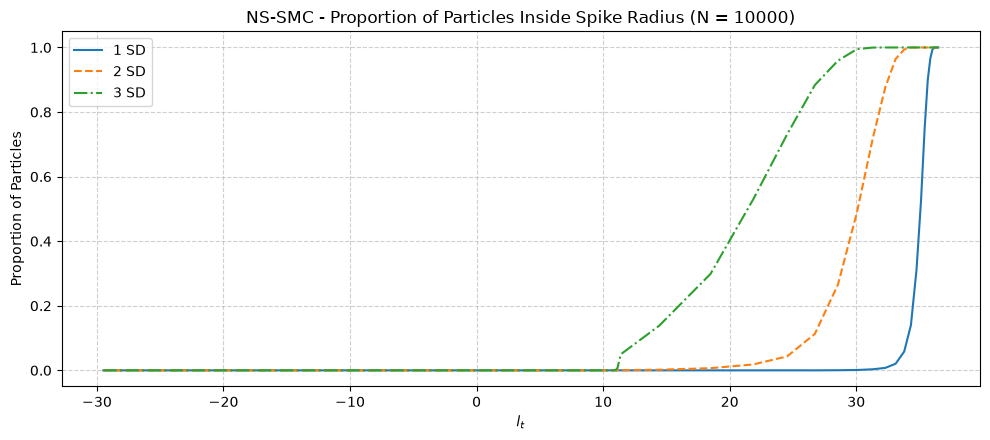

In [393]:
# Proportion of Particles Inside Spike Radius (1sd, 2sd, 3sd) Over the Log Likelihood Thresholds
plt.figure(figsize=(10, 4.5))

plt.plot(
    levels, 
    prop_particles_inside_spike_radius_1sd_ns_smc,
    label="1 SD",
    linewidth=1.5,
    color="tab:blue",
)
plt.plot(
    levels, 
    prop_particles_inside_spike_radius_2sd_ns_smc,
    label="2 SD",
    linestyle="--",
    linewidth=1.5,
    color="tab:orange",
)
plt.plot(
    levels, 
    prop_particles_inside_spike_radius_3sd_ns_smc,
    label="3 SD",
    linestyle="-.",
    linewidth=1.5,
    color="tab:green",
)

plt.xlabel(r"$l_t$")
plt.ylabel("Proportion of Particles")
plt.title(f"NS-SMC - Proportion of Particles Inside Spike Radius (N = {options.N})")
plt.ylim(-0.05, 1.05)
plt.legend(loc="best")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

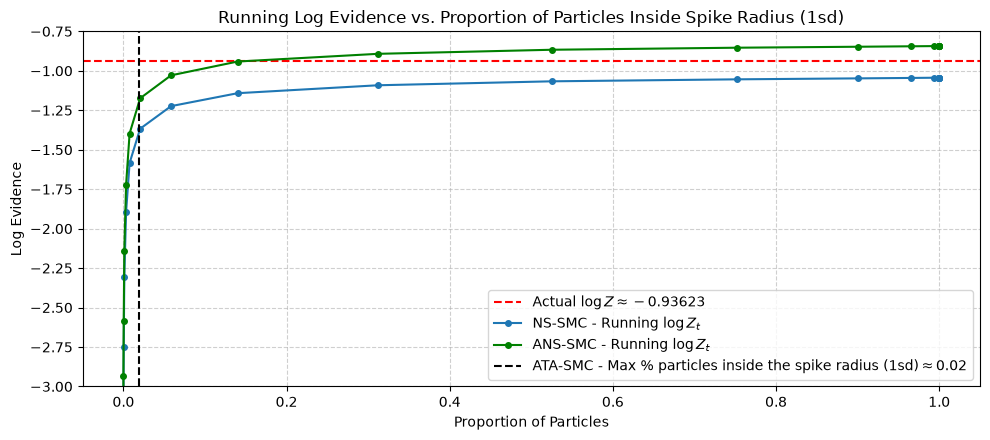

In [394]:
# Log Evidence vs. Proportion of Particles Inside Spike Radius (1sd) for ANS-SMC, NS-SMC and ATA-SMC
plt.figure(figsize=(10, 4.5))
plt.axhline(y=np.log(0.3921), color="r", linestyle="--", linewidth=1.5, label=r"Actual $\log Z\approx-0.93623$")
plt.plot(prop_particles_inside_spike_radius_1sd_ns_smc[1:], log_evidence_t_ns_smc, marker="o", linewidth=1.5, markersize=4, label=r"NS-SMC - Running $\log Z_t$")
plt.plot(prop_particles_inside_spike_radius_1sd_ns_smc[1:], log_evidence_t_ans_smc, marker="o", linewidth=1.5, markersize=4, label=r"ANS-SMC - Running $\log Z_t$", color="green")
plt.axvline(x=np.max(prop_particles_inside_spike_radius_1sd_ata_smc), color="black", linestyle="--", linewidth=1.5, label=r"ATA-SMC - Max % particles inside the spike radius (1sd)$\approx$0.02")
plt.xlabel(r"Proportion of Particles")
plt.ylabel("Log Evidence")
plt.ylim(-3, -0.75)
plt.title(rf"Running Log Evidence vs. Proportion of Particles Inside Spike Radius (1sd)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()